# Traditional-CV Defect Baseline — HRIPCB
### `notebooks/01_traditional_baseline.ipynb` · pcb-aoi · Stage 1

A **reference-vs-test** classical pipeline: every HRIPCB defect image is derived
from one of ten clean `PCB_USED` templates, so after homography registration a
colour-difference exposes the introduced defects, which morphology + connected
components segment and a small rule-based classifier labels.

This is the *baseline* the deep-learning stages (2: CNN classifier, 3: YOLO
detector) must beat. Code lives in
[`src/traditional_cv.py`](../src/traditional_cv.py); evaluation in
[`src/evaluate_traditional.py`](../src/evaluate_traditional.py).

## 1. Algorithm

```
test image + template
   -> register_to_template   ORB features + RANSAC homography  (warp test -> template frame)
   -> compute_difference     max abs diff over B/G/R channels  (colour, not luminance)
   -> threshold_and_clean    binarise + morph open/close + area filter
   -> classify_components     connected components -> shape features -> nearest-prototype class
```

Two design choices proved decisive (see Stage-1 report for the evidence):

1. **Colour difference, not grayscale.** PCB defects are mostly
   copper(orange)-vs-substrate(green) changes that barely move luminance — a
   grayscale diff misses `short`/`spur`/`mouse_bite` almost entirely.
2. **Tight mask for shape, padded box for IoU.** Features are measured on the
   tight difference blob (so elongation / circularity stay discriminative) while
   the *reported* box is expanded toward the generous VOC annotation scale.

pipeline config: {'register_method': 'orb', 'blur_ksize': 3, 'threshold': 22, 'morph_open_ksize': 3, 'morph_close_ksize': 5, 'dilate_ksize': 0, 'bbox_pad': 16, 'min_area': 40, 'max_area': 50000}


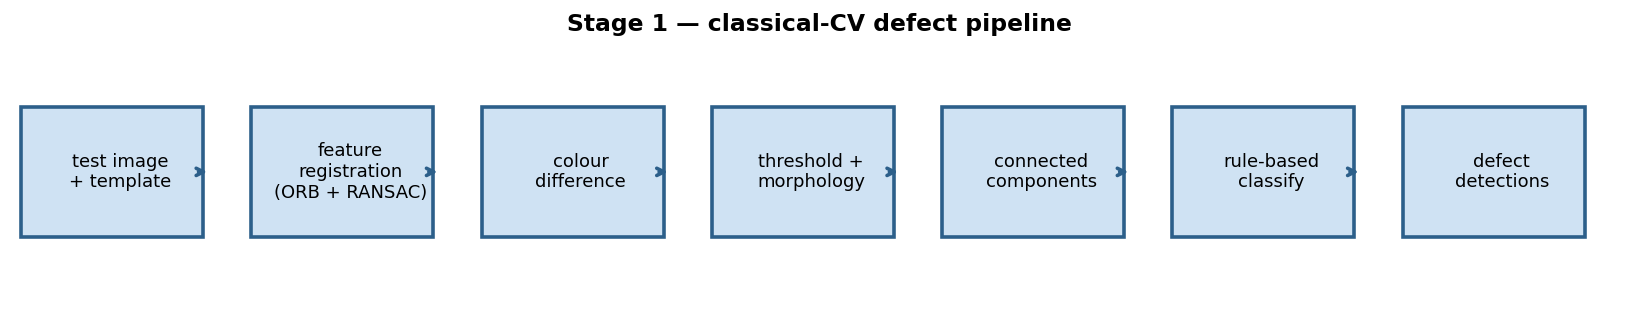

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if (Path.cwd() / "01_traditional_baseline.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path(r"D:\ash-portfolio\pcb-aoi")
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
import pandas as pd
from src.traditional_cv import DEFAULT_CONFIG
from src.hripcb import CLASSES, CLASS_ZH
FIG = ROOT / "results" / "figures"
print("pipeline config:", DEFAULT_CONFIG)
display(Image(filename=str(FIG / "01_pipeline_diagram.png")))

## 2. Step-by-step on single images

Each strip shows all six intermediate stages. **Green = ground truth**, coloured
boxes = predictions. First an *easy* class (`missing_hole`), then a *hard* one
(`mouse_bite`).

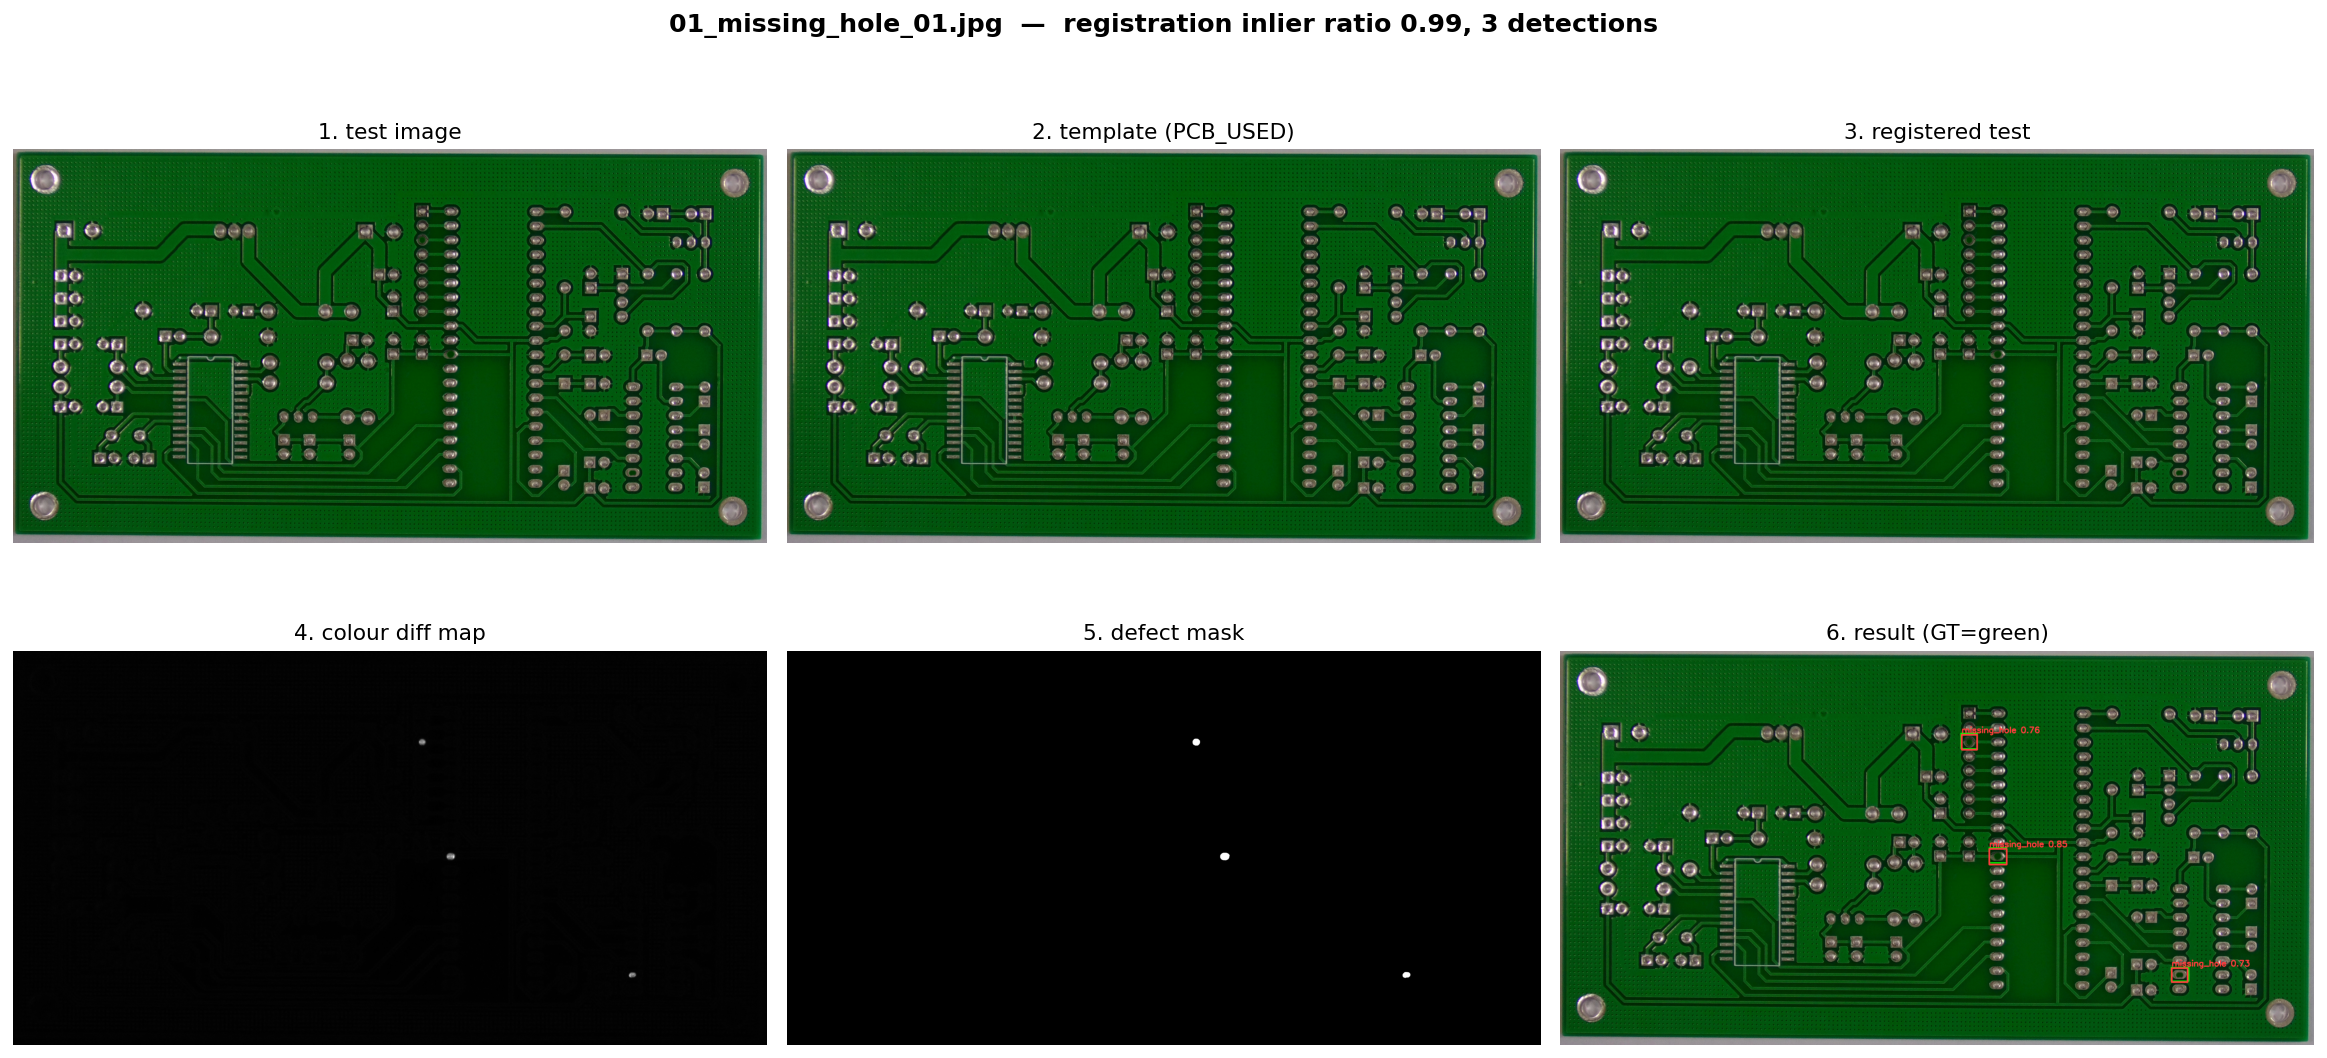

In [2]:
display(Image(filename=str(FIG / "01_step_by_step_missing_hole.png")))

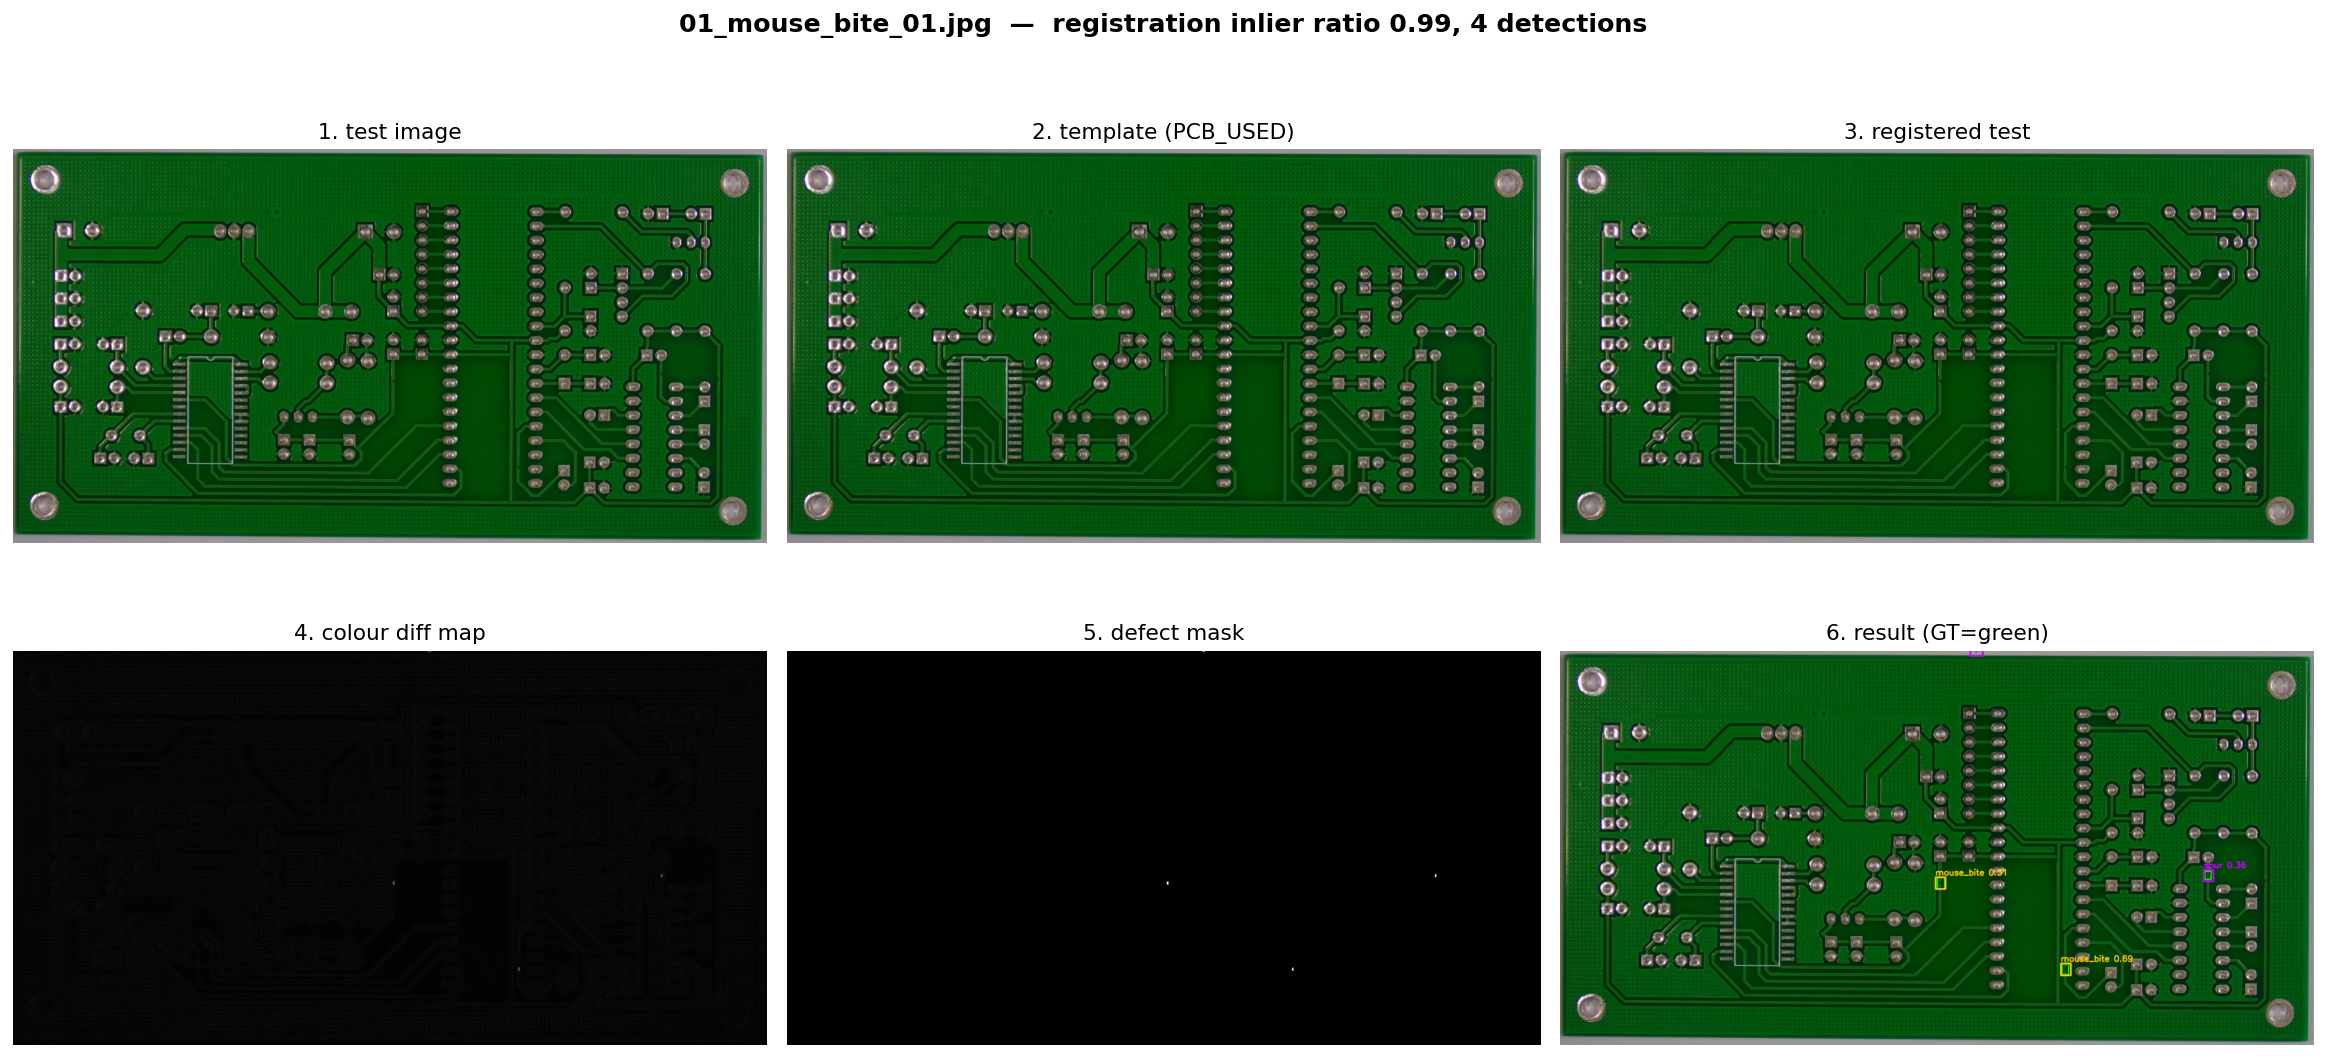

In [3]:
display(Image(filename=str(FIG / "01_step_by_step_mouse_bite.png")))

## 3. One result per class

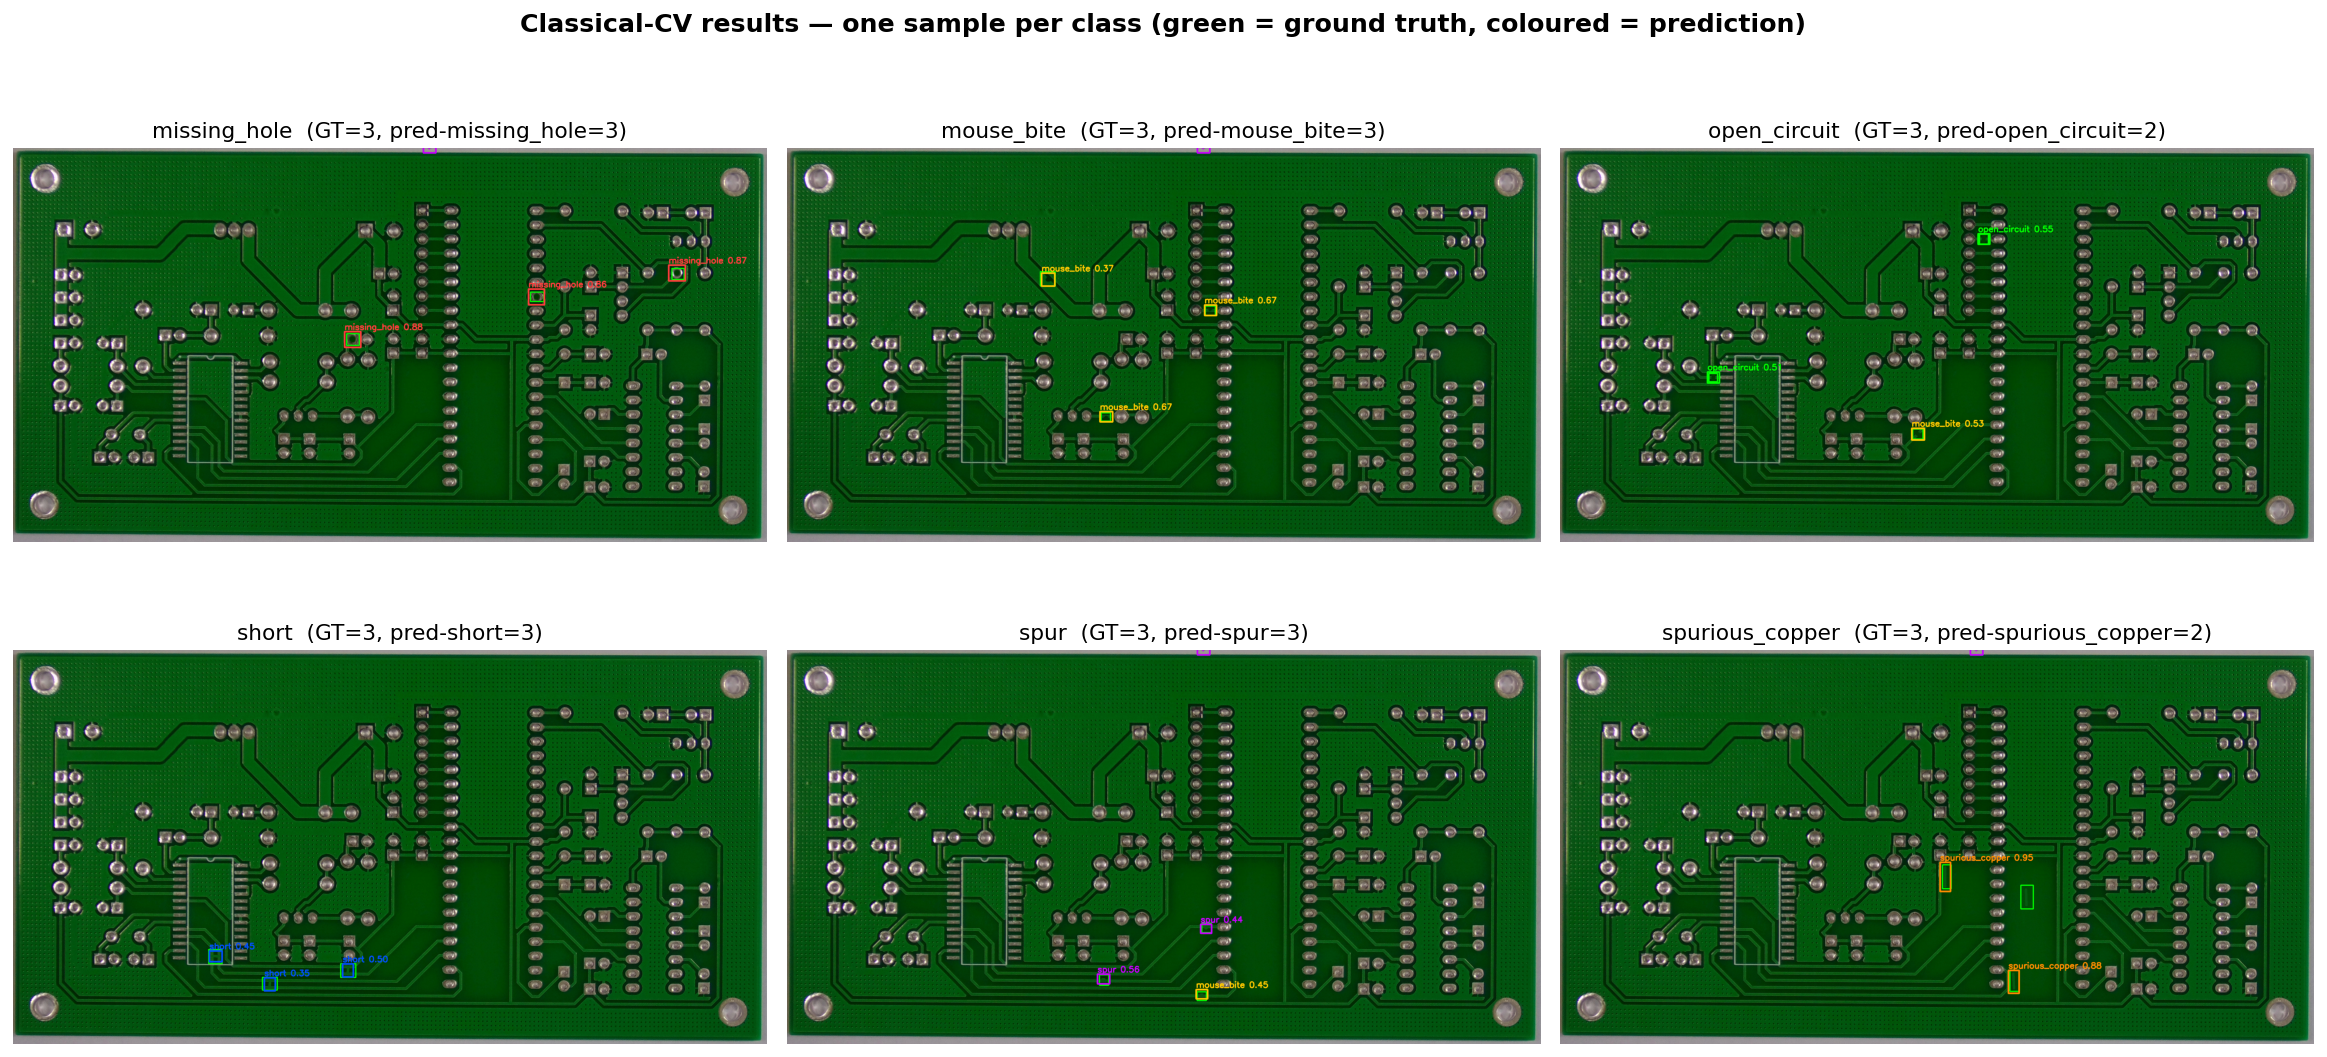

In [4]:
display(Image(filename=str(FIG / "01_per_class_results.png")))

## 4. Full-dataset evaluation (all 693 images)

Predictions are matched to VOC ground truth at **IoU ≥ 0.5**; mAP@0.5 is the mean
of per-class average precision. Numbers are loaded from
`results/traditional_eval_summary.json` (regenerate with
`python -m src.evaluate_traditional`).

In [5]:
res = json.loads((ROOT / "results" / "traditional_eval_summary.json").read_text())
rows = []
for c in CLASSES:
    m = res["per_class"][c]
    rows.append({"class": c, "中文": CLASS_ZH[c],
                 "precision": round(m["precision"], 3), "recall": round(m["recall"], 3),
                 "f1": round(m["f1"], 3), "AP@0.5": round(m["ap"], 3),
                 "TP": m["tp"], "FP": m["fp"], "FN": m["fn"]})
df = pd.DataFrame(rows)
print(f"mAP@0.5 = {res['mAP@0.5']*100:.1f}%   over {res['n_images']} images")
df

mAP@0.5 = 27.4%   over 693 images


,class,中文,precision,recall,f1,AP@0.5,TP,FP,FN
0,missing_hole,缺孔,0.496,0.964,0.655,0.898,479,487,18
1,mouse_bite,鼠咬(缺口),0.238,0.134,0.172,0.049,66,211,426
2,open_circuit,斷路,0.279,0.064,0.105,0.024,31,80,451
3,short,短路,0.297,0.310,0.303,0.160,152,359,339
4,spur,毛刺(凸尖),0.171,0.049,0.076,0.019,24,116,464
5,spurious_copper,多餘銅(殘銅),0.395,0.845,0.538,0.496,425,652,78


In [6]:
t = res["timing"]; r = res["registration"]
print(f"speed       : mean {t['mean_s_per_image']:.2f}s/img, median {t['median_s_per_image']:.2f}s, max {t['max_s_per_image']:.2f}s")
print(f"registration: mean inlier ratio {r['mean_inlier_ratio']:.3f}, min {r['min_inlier_ratio']:.3f}, frac<0.3 {r['frac_below_0.3']*100:.1f}%")

speed       : mean 0.79s/img, median 0.81s, max 0.97s
registration: mean inlier ratio 0.991, min 0.944, frac<0.3 0.0%


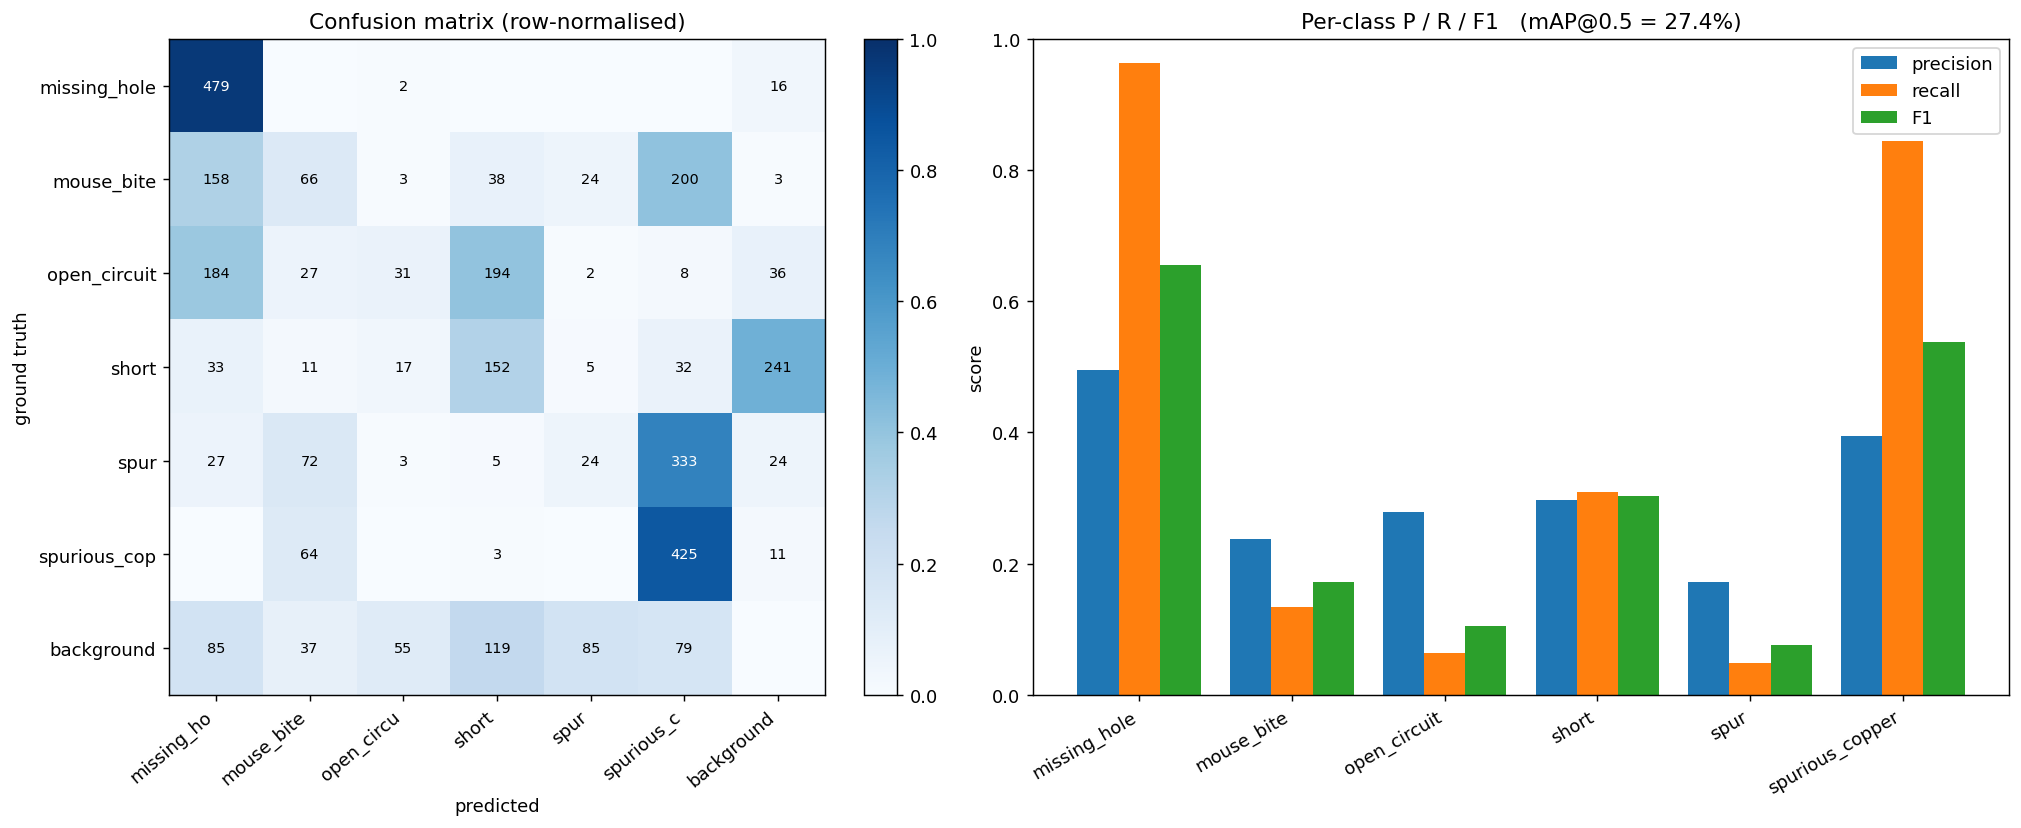

In [7]:
display(Image(filename=str(FIG / "01_evaluation_summary.png")))

## 5. Takeaways

See [`results/traditional_baseline_report.md`](../results/traditional_baseline_report.md)
for the full write-up. In short: registration is essentially perfect and
localisation works, but **fine-grained classification of the small defects
(`mouse_bite` / `open_circuit` / `spur`) is the wall** — the motivation for the
learned models in Stage 2 and Stage 3.